# Okna na flaty na niebie (wk06, zb08, jk15)

Kiedy można robić flaty w danym filtrze i w jakiej kolejności. Dane: log flatów TOI z NATS
(`tic.status.<tel>.toi.flat`, jedna wiadomość na klatkę: `mean`, `exp_time`, `filter`, `timestamp_utc`; strumień `tic_status` trzyma 30 dni).

1. pobranie logu z NATS
2. wysokość Słońca w środku ekspozycji i jasność nieba na sekundę
3. model jasności nieba i reszty
4. okna, sekwencje 7/7, plan i wykres

Limity z konfiguracji TIC (`ocabox-config-ocm/config.yaml`, `camera.sky_flats`): wk06 i zb08 20–25 kADU, ekspozycja 2–120 s; jk15 40–60 kADU, 10–120 s.

In [1]:
import asyncio, json, os
import numpy as np
import pandas as pd
import ephem
import matplotlib.pyplot as plt
import nats
from nats.js.api import ConsumerConfig, DeliverPolicy

DATA = "/home/mgorski/data/flats/flat_log.parquet"
TELS = ["wk06", "zb08", "jk15"]

## 1. Pobranie logu flatów z NATS

Tylko odczyt (consumer ordered, efemeryczny). Czyta stary temat `tic.status.<tel>.toi.flat` i nowy `data.toi.<tel>.camera.flat_log` (od 2026-11-10; jeśli nie ma dla niego strumienia, nic z niego nie przyjdzie).
Nowe klatki są dopisywane do pliku `DATA` (strumień trzyma ~30 dni, więc plik zbiera dłuższą historię); jeśli nie trzeba nowych danych, tę komórkę można pominąć.

In [2]:
NATS_URL = "nats://nats.oca.lan:4222"
SUBJECTS = ["tic.status.*.toi.flat", "data.toi.*.camera.flat_log"]

async def read_all(js, subject):
    out = []
    try:
        sub = await js.subscribe(subject, ordered_consumer=True, config=ConsumerConfig(deliver_policy=DeliverPolicy.ALL))
    except Exception as e:
        print(subject, "- brak strumienia:", e)
        return out
    while True:
        try:
            msg = await sub.next_msg(timeout=10)
        except nats.errors.TimeoutError:
            break
        out.append(dict(subject=msg.subject, **json.loads(msg.data).get("data", {})))
        if msg.metadata.num_pending == 0:
            break
    await sub.unsubscribe()
    return out

nc = await nats.connect(NATS_URL, connect_timeout=5)
js = nc.jetstream()
rows = []
for s in SUBJECTS:
    rows += await read_all(js, s)
await nc.close()

log = pd.DataFrame(rows)
log["telescope"] = log.subject.str.split(".").str[2]
if os.path.exists(DATA):
    log = pd.concat([pd.read_parquet(DATA), log])
log = log.drop_duplicates(["telescope", "timestamp_utc"]).sort_values("timestamp_utc")
log.to_parquet(DATA)
print(len(log), "klatek,", log.timestamp_utc.min(), "..", log.timestamp_utc.max())
print(log.groupby(["telescope", "filter"]).size().unstack(0))

1025 klatek, 2026-10-29 23:00:09.539793 .. 2026-11-07 23:30:17.687646
telescope  jk15  wk06  zb08
filter                     
B          21.0  42.0  45.0
Ha_n       14.0   NaN   NaN
Ha_w        7.0   NaN   NaN
Hb_n       10.0   7.0   NaN
Hb_w        7.0   7.0   NaN
Ic         14.0  63.0  51.0
V          14.0  42.0  35.0
b_s        12.0  42.0   NaN
g           7.0   NaN  49.0
i           7.0   NaN  70.0
r          14.0   NaN  73.0
u           7.0   NaN  77.0
u_s         7.0  70.0   NaN
v_s         7.0  68.0   NaN
y_s         7.0  52.0   NaN
z           7.0   NaN  70.0


## 2. Wysokość Słońca i jasność nieba

`h_sun` zapisane przez TOI jest przy horyzoncie zawyżone nawet o 1.5° (wygląda na refrakcję liczoną też pod horyzontem), więc wysokość liczę sama: geometryczna (bez refrakcji), w środku ekspozycji.
`timestamp_utc` to koniec klatki; środek = timestamp − exp/2 − 5 s (odczyt).

Jasność nieba = (mean − bias) / exp_time [ADU/s]. Bias: wk06, zb08 300; jk15 3817 (tryb g-1_r-3).
Wieczór / rano po godzinie UT (wieczorne flaty ~23 UT, poranne ~9 UT).

In [3]:
BIAS = {"wk06": 300, "zb08": 300, "jk15": 3817}

df = pd.read_parquet(DATA)
df["t"] = pd.to_datetime(df.timestamp_utc)
df["sess"] = np.where(df.t.dt.hour > 16, "evening", "morning")

ocm = ephem.Observer()
ocm.lat, ocm.lon, ocm.elevation, ocm.pressure = "-24.598", "-70.196", 2817, 0
sun = ephem.Sun()
def sun_alt(t):
    ocm.date = t.to_pydatetime()
    sun.compute(ocm)
    return np.degrees(sun.alt)

df["h"] = [sun_alt(t - pd.Timedelta(seconds=e / 2 + 5)) for t, e in zip(df.t, df.exp_time)]
df["h_toi"] = df.h_sun.astype(float)
df["rate"] = (df["mean"] - df.telescope.map(BIAS)) / df.exp_time

# czasy martwe z kolejnych klatek: odczyt (klatki 2..7 serii) i zmiana filtra z ekspozycją testową (klatka 1)
df = df.sort_values("t")
df["ovh"] = df.groupby("telescope").t.diff().dt.total_seconds() - df.exp_time
OVH = {t: df[(df.telescope == t) & (df.n_exp > 1)].ovh.median() for t in TELS}
CHG = {t: df[(df.telescope == t) & (df.n_exp == 1) & (df.ovh < 900)].ovh.median() for t in TELS}
TARGET = {t: (df[df.telescope == t]["mean"] - BIAS[t]).median() for t in TELS}   # poziom, który TIC faktycznie osiąga
print("odczyt [s]:", {t: round(v, 1) for t, v in OVH.items()})
print("zmiana filtra [s]:", {t: round(v, 1) for t, v in CHG.items()})
print("poziom nad biasem [ADU]:", TARGET)
print("h_sun TOI - h geometryczne (koniec klatki):")
print((df.h_toi - [sun_alt(t) for t in df.t]).describe().round(2))

odczyt [s]: {'wk06': np.float64(11.6), 'zb08': np.float64(15.1), 'jk15': np.float64(34.8)}
zmiana filtra [s]: {'wk06': np.float64(30.9), 'zb08': np.float64(30.6), 'jk15': np.float64(82.5)}
poziom nad biasem [ADU]: {'wk06': np.float64(19938.0), 'zb08': np.float64(19711.0), 'jk15': np.float64(37409.0)}
h_sun TOI - h geometryczne (koniec klatki):
count    1025.00
mean        0.62
std         0.55
min        -0.01
25%         0.13
50%         0.36
75%         1.18
max         1.49
Name: h_toi, dtype: float64


/tmp/ipykernel_509279/4262428989.py:11: UserWarning: Discarding nonzero nanoseconds in conversion.
  ocm.date = t.to_pydatetime()


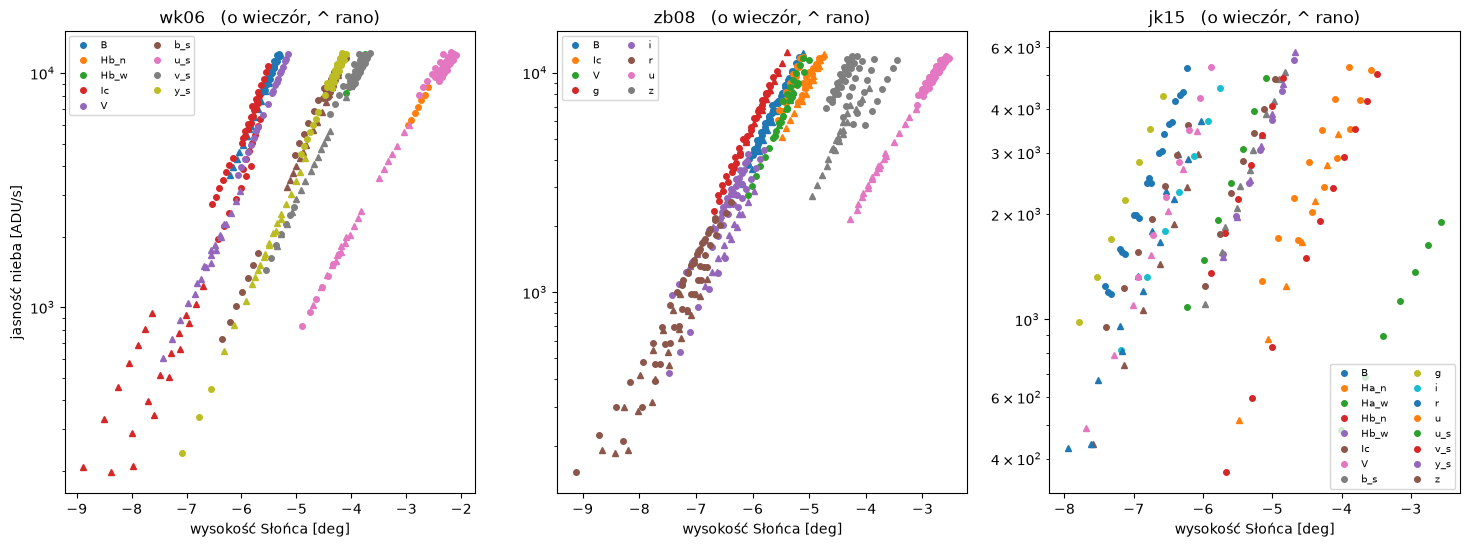

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, tel in zip(axs, TELS):
    d = df[df.telescope == tel]
    for i, (f, g) in enumerate(d.groupby("filter")):
        ax.semilogy(g[g.sess == "evening"].h, g[g.sess == "evening"].rate, "o", color=f"C{i % 10}", ms=4, label=f)
        ax.semilogy(g[g.sess == "morning"].h, g[g.sess == "morning"].rate, "^", color=f"C{i % 10}", ms=4)
    ax.set_title(f"{tel}   (o wieczór, ^ rano)")
    ax.set_xlabel("wysokość Słońca [deg]")
    ax.legend(fontsize=7, ncol=2)
axs[0].set_ylabel("jasność nieba [ADU/s]")
plt.show()

## 3. Model jasności nieba

Dla każdego teleskopu jeden kształt zmierzchu i stała na filtr:

log10(rate) = a1·h + a2·h² + s·(rano) + c_filtr

Rano niebo przy tej samej wysokości Słońca wychodzi nieco ciemniejsze (s < 0). Klatki z h < −9.5° pominięte (tło nocne).
Filtr z małą liczbą klatek dostaje tylko swoją stałą, kształt bierze od innych.

wk06 a1 = 0.324  a2 = -0.0170  rano = -0.041  rms reszt = 0.065 dex
   od najciemniejszego: u_s, Hb_n, v_s, Hb_w, y_s, b_s, V, Ic, B
zb08 a1 = 0.229  a2 = -0.0193  rano = -0.074  rms reszt = 0.072 dex
   od najciemniejszego: u, z, i, r, V, Ic, B, g
jk15 a1 = 0.394  a2 = -0.0107  rano = -0.139  rms reszt = 0.038 dex
   od najciemniejszego: u_s, Hb_n, Ha_n, u, Hb_w, v_s, z, Ha_w, y_s, b_s, i, Ic, V, r, B, g


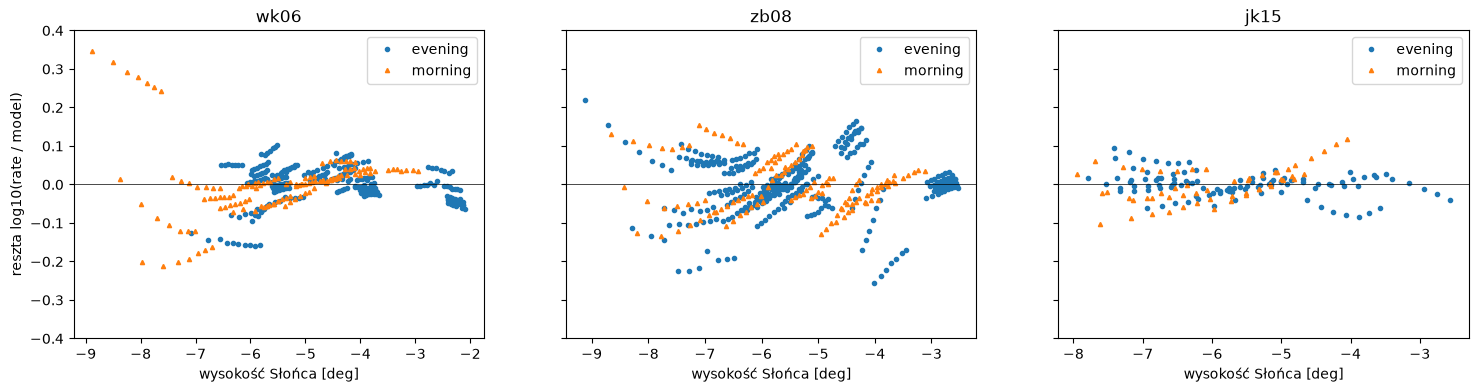

In [5]:
MODEL = {}
for tel in TELS:
    d = df[(df.telescope == tel) & (df.h > -9.5)]
    fs = sorted(d["filter"].unique())
    X = np.column_stack([d.h, d.h**2, (d.sess == "morning")] + [(d["filter"] == f) for f in fs]).astype(float)
    c, *_ = np.linalg.lstsq(X, np.log10(d.rate), rcond=None)
    MODEL[tel] = dict(a1=c[0], a2=c[1], s=c[2], cf=dict(zip(fs, c[3:])))
    MODEL[tel]["filters"] = sorted(fs, key=lambda f: MODEL[tel]["cf"][f])     # od najciemniejszego
    print(tel, "a1 = %.3f  a2 = %.4f  rano = %.3f" % tuple(c[:3]), " rms reszt = %.3f dex" % (np.log10(d.rate) - X @ c).std())
    print("   od najciemniejszego:", ", ".join(MODEL[tel]["filters"]))

def rate(tel, f, h, sess):
    m = MODEL[tel]
    return 10 ** (m["a1"] * h + m["a2"] * h**2 + m["cf"][f] + (m["s"] if sess == "morning" else 0))

df["res"] = [np.log10(r / rate(t, f, h, s)) for r, t, f, h, s in zip(df.rate, df.telescope, df["filter"], df.h, df.sess)]
fig, axs = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, tel in zip(axs, TELS):
    d = df[df.telescope == tel]
    for s, m in [("evening", "o"), ("morning", "^")]:
        ax.plot(d[d.sess == s].h, d[d.sess == s].res, m, ms=3, label=s)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(tel)
    ax.set_xlabel("wysokość Słońca [deg]")
    ax.legend()
axs[0].set_ylabel("reszta log10(rate / model)")
axs[0].set_ylim(-0.4, 0.4)
plt.show()

## 4. Okna, sekwencje 7/7 i plan

- **Okno**: chwile, gdy ekspozycja (poziom `TARGET` / jasność, obcięta do limitów TIC) daje poziom w zakresie ADU TIC.
- **Sekwencja 7/7**: zmiana filtra + 7 klatek po (ekspozycja + odczyt), ekspozycja liczona na początku każdej klatki; nie mieści się, jeśli któraś klatka wypada poza zakres. Na wykresie jej najkrótsze położenie (wieczorem na początku okna, rano na końcu).
- **Plan**: wieczorem od początku, za każdym razem filtr, któremu okno zamyka się najwcześniej; rano od wschodu wstecz, filtr, któremu okno otwiera się najpóźniej, każda sekwencja jak najpóźniej (krótkie ekspozycje).
- Oś czasu dla jednej nocy (`NIGHT`); τ = minuty od zachodu (wieczór) albo minus minuty do wschodu (rano), żeby czas zawsze płynął w prawo.

In [6]:
NIGHT = "2026/11/10 18:00"    # lokalne popołudnie przed nocą (UT)
NSEQ = 7
EXP = {"wk06": (2, 120), "zb08": (2, 120), "jk15": (10, 120)}                       # s
ADU = {"wk06": (20000, 25000), "zb08": (20000, 25000), "jk15": (40000, 60000)}     # test_adu_range, z biasem

ocm.pressure = 1010    # zachód / wschód jak zwykle (z refrakcją, górny brzeg)
ocm.date = NIGHT
sunset = ocm.next_setting(sun).datetime()
sunrise = ocm.next_rising(sun).datetime()
ocm.pressure = 0
grid = np.arange(-20, 121, 0.25)                                                       # minuty
H_EVE = np.array([sun_alt(pd.Timestamp(sunset) + pd.Timedelta(minutes=m)) for m in grid])
H_MOR = np.array([sun_alt(pd.Timestamp(sunrise) - pd.Timedelta(minutes=m)) for m in grid])
print("zachód", sunset, " wschód", sunrise, "UT")

def h_of_min(m, sess):     # minuty od zachodu / do wschodu -> wysokość Słońca
    return np.interp(m, grid, H_EVE if sess == "evening" else H_MOR)

def min_of_h(h, sess):
    H = H_EVE if sess == "evening" else H_MOR
    return np.interp(h, H[::-1], grid[::-1])

def tmin(tau, sess):       # tau (czas w prawo) -> minuty od zachodu / do wschodu
    return tau if sess == "evening" else -tau

def ok_rate(tel, rt):
    e = np.clip(TARGET[tel] / rt, *EXP[tel])
    lev = rt * e + BIAS[tel]
    return (lev >= ADU[tel][0] * 0.98) & (lev <= ADU[tel][1]), e

def window(tel, f, sess):
    ok, _ = ok_rate(tel, rate(tel, f, h_of_min(grid, sess), sess))
    ok &= h_of_min(grid, sess) < 1
    if not ok.any():
        return None
    m = grid[ok]
    return (m.min(), m.max()) if sess == "evening" else (-m.max(), -m.min())

def seq_dur(tel, f, sess, tau0):
    tau = tau0 + CHG[tel] / 60
    for k in range(NSEQ):
        ok, e = ok_rate(tel, rate(tel, f, h_of_min(tmin(tau, sess), sess), sess))
        if not ok:
            return None
        tau += (e + OVH[tel]) / 60
    return tau - tau0

def fastest(tel, f, sess):
    best = None
    for t0 in np.arange(-130, 130, 0.25):
        d = seq_dur(tel, f, sess, t0)
        if d is not None and (best is None or d < best[1] - 1e-9):
            best = (t0, d)
    return best

def plan(tel, sess):
    wins = {f: window(tel, f, sess) for f in MODEL[tel]["filters"]}
    todo = {f for f in wins if wins[f]}
    out = []
    if sess == "evening":
        tau = min(wins[f][0] for f in todo)
        while todo and tau < 130:
            cand = [(wins[f][1], f) for f in todo if seq_dur(tel, f, sess, tau) is not None]
            if not cand:
                tau += 0.25
                continue
            f = min(cand)[1]
            d = seq_dur(tel, f, sess, tau)
            out.append((f, tau, d))
            tau += d
            todo.remove(f)
    else:
        tend = max(wins[f][1] for f in todo)
        while todo and tend > -130:
            cand = []
            for f in todo:
                for t0 in np.arange(tend - 0.25, tend - 25, -0.25):
                    d = seq_dur(tel, f, sess, t0)
                    if d is not None and t0 + d <= tend:
                        cand.append((-wins[f][0], f, t0, d))
                        break
            if not cand:
                tend -= 0.25
                continue
            _, f, t0, d = min(cand)
            out.append((f, t0, d))
            tend = t0
            todo.remove(f)
        out = out[::-1]
    return out, [f for f in MODEL[tel]["filters"] if f in todo]

for tel in TELS:
    for sess in ["evening", "morning"]:
        p, left = plan(tel, sess)
        print(f"{tel} {sess:8s}", " -> ".join(x[0] for x in p), f"({sum(x[2] for x in p):.0f} min)", "| nie mieszczą się:", ", ".join(left) or "-")

zachód 2026-11-10 23:01:46.601905  wschód 2026-11-11 09:47:30.556052 UT
wk06 evening  Hb_n -> u_s -> Hb_w -> v_s -> y_s -> b_s -> V -> Ic -> B (22 min) | nie mieszczą się: -
wk06 morning  B -> Ic -> V -> b_s -> y_s -> v_s -> Hb_w -> u_s -> Hb_n (23 min) | nie mieszczą się: -
zb08 evening  u -> z -> i -> Ic -> V -> r -> B (23 min) | nie mieszczą się: g


zb08 morning  g -> r -> V -> Ic -> i -> z -> u (23 min) | nie mieszczą się: B
jk15 evening  u_s -> Hb_n -> Hb_w -> Ic (32 min) | nie mieszczą się: Ha_n, u, v_s, z, Ha_w, y_s, b_s, i, V, r, B, g


jk15 morning  Ic -> Hb_w -> Hb_n -> u_s (31 min) | nie mieszczą się: Ha_n, u, v_s, z, Ha_w, y_s, b_s, i, V, r, B, g


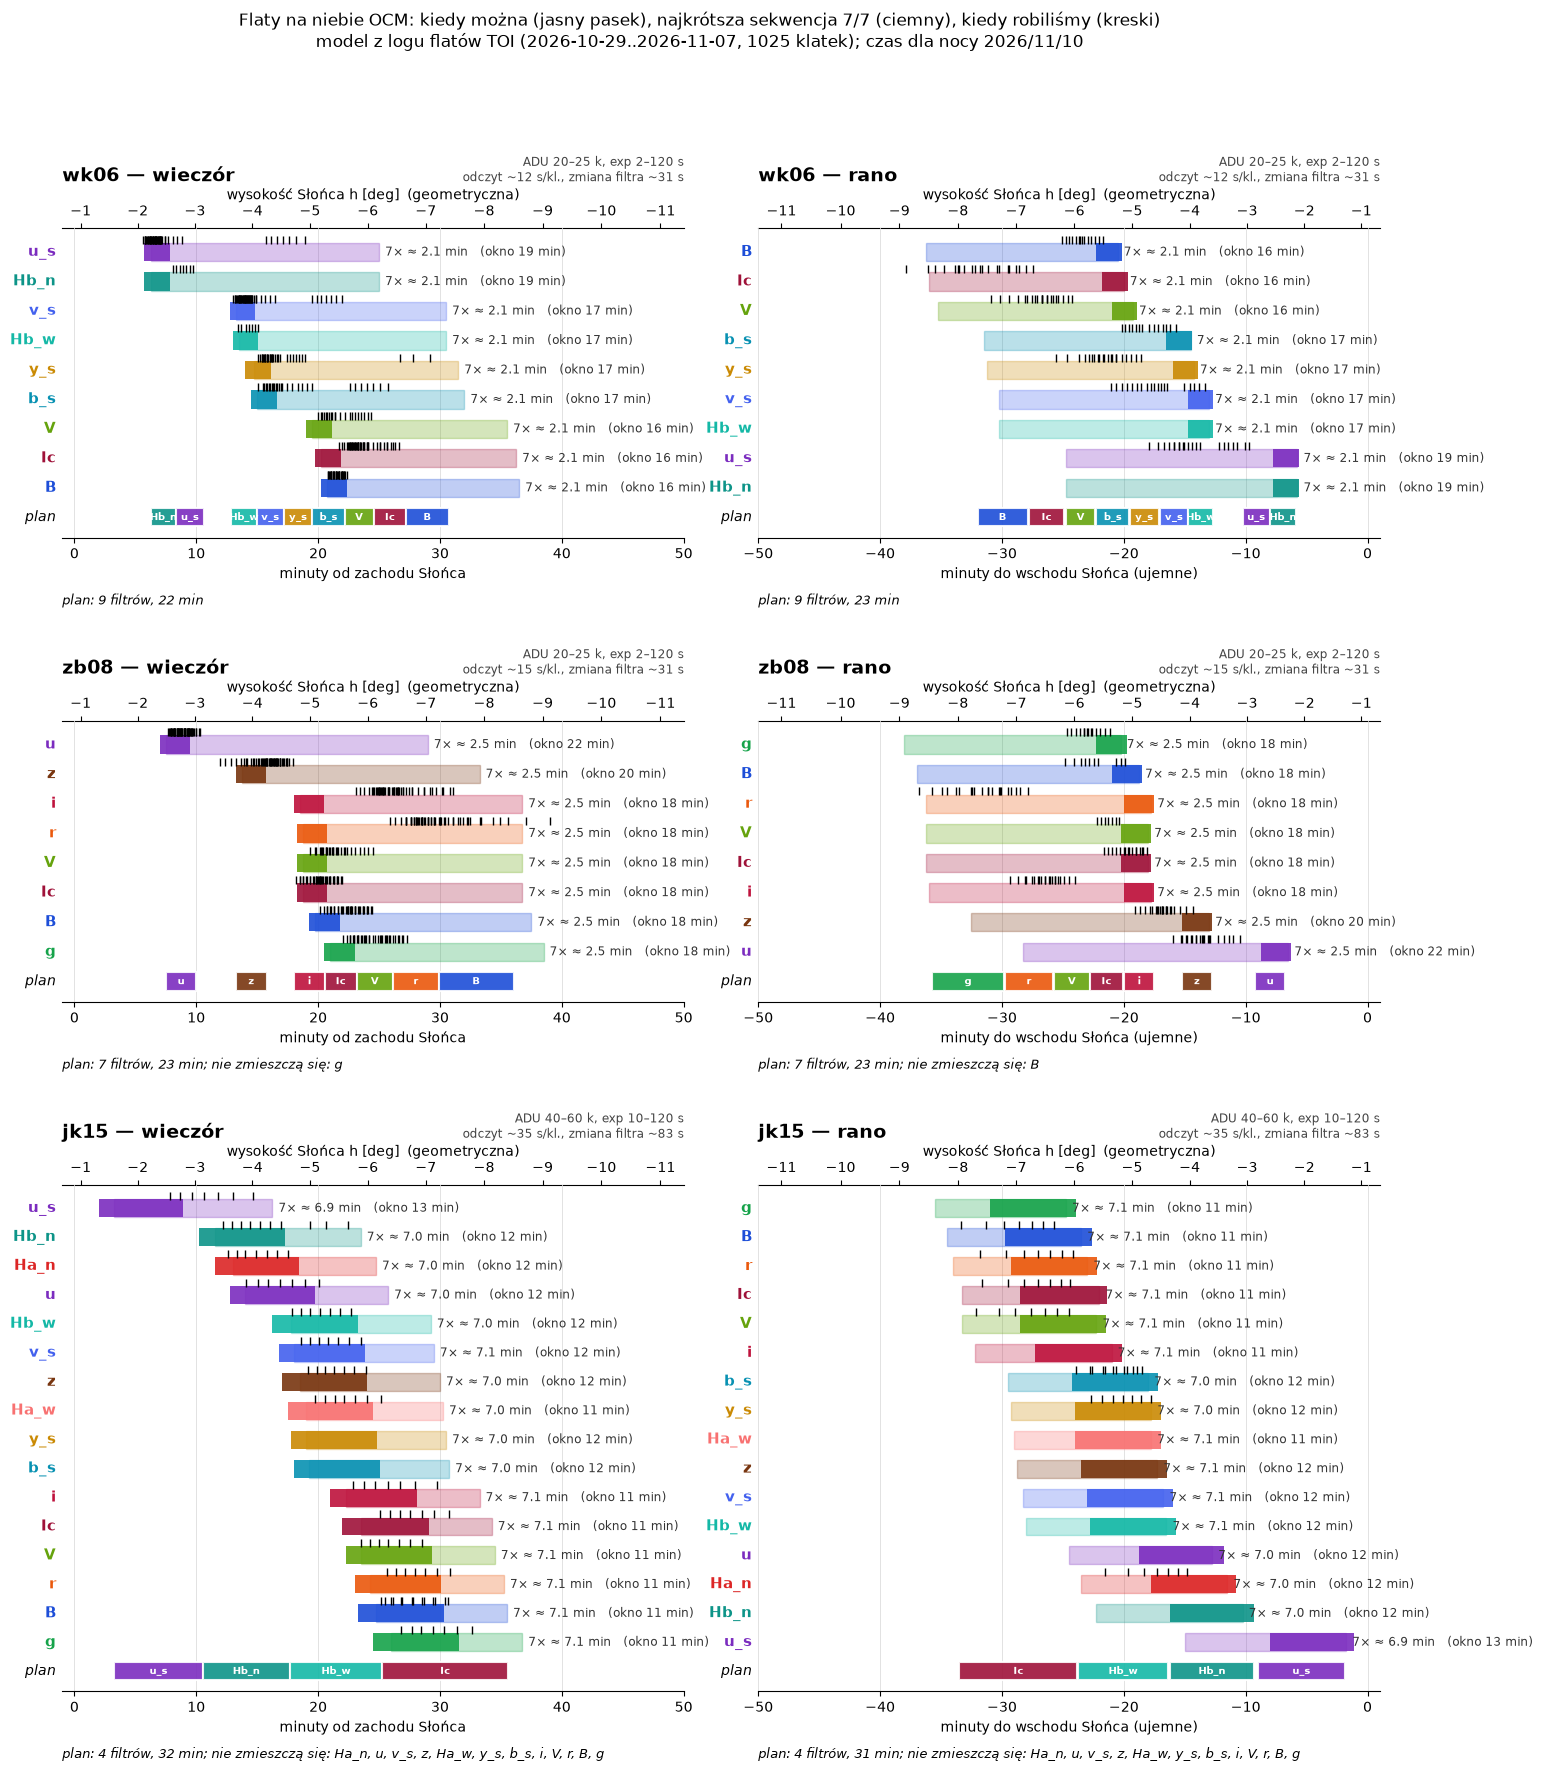

In [7]:
COL = {"u": "#7b2cbf", "u_s": "#7b2cbf", "v_s": "#4361ee", "B": "#1d4ed8", "b_s": "#0891b2", "Hb_n": "#0d9488", "Hb_w": "#14b8a6",
       "g": "#16a34a", "V": "#65a30d", "y_s": "#ca8a04", "r": "#ea580c", "Ha_n": "#dc2626", "Ha_w": "#f87171", "Ic": "#9f1239", "i": "#be123c", "z": "#78350f"}

fig, axs = plt.subplots(3, 2, figsize=(17, 19), gridspec_kw=dict(height_ratios=[len(MODEL[t]["filters"]) + 2 for t in TELS], hspace=0.5, wspace=0.12))
for r, tel in enumerate(TELS):
    for c, sess in enumerate(["evening", "morning"]):
        ax = axs[r, c]
        fl = sorted(MODEL[tel]["filters"], key=lambda f: (window(tel, f, sess) or (999,))[0])
        obs = df[(df.telescope == tel) & (df.sess == sess)]
        for y, f in enumerate(fl):
            yy = len(fl) - y
            w = window(tel, f, sess)
            if w:
                ax.barh(yy, w[1] - w[0], left=w[0], height=0.62, color=COL[f], alpha=0.28, edgecolor=COL[f], lw=1)
                fb = fastest(tel, f, sess)
                if fb:
                    ax.barh(yy, fb[1], left=fb[0], height=0.62, color=COL[f], alpha=0.9)
                txt = f"7× ≈ {fb[1]:.1f} min" if fb else "7× nie mieści się"
                ax.text(w[1] + 0.5, yy, f"{txt}   (okno {w[1] - w[0]:.0f} min)", va="center", fontsize=8.5, color="#333")
            ax.text(-0.01, yy, f, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=11, fontweight="bold", color=COL[f])
            o = obs[obs["filter"] == f]
            ax.plot(tmin(min_of_h(o.h.values, sess), sess), np.full(len(o), yy + 0.42), "|", color="k", ms=6, mew=1)
        p, left = plan(tel, sess)
        for f, t0, d in p:
            ax.barh(0, d, left=t0, height=0.62, color=COL[f], alpha=0.9, edgecolor="white", lw=1.5)
            if d > 1.6:
                ax.text(t0 + d / 2, 0, f, ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
        ax.text(-0.01, 0, "plan", transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=10, style="italic")
        txt = f"plan: {len(p)} filtrów, {sum(x[2] for x in p):.0f} min" + (f"; nie zmieszczą się: {', '.join(left)}" if left else "")
        ax.annotate(txt, xy=(0, 0), xycoords="axes fraction", xytext=(0, -40), textcoords="offset points", ha="left", va="top", fontsize=9, style="italic")
        ax.set_yticks([])
        ax.set_ylim(-0.7, len(fl) + 0.8)
        ax.set_xlim(*((-1, 50) if sess == "evening" else (-50, 1)))
        ax.grid(axis="x", color="#ddd", lw=0.6)
        ax.set_axisbelow(True)
        for s in ["top", "right", "left"]:
            ax.spines[s].set_visible(False)
        ax.set_xlabel("minuty od zachodu Słońca" if sess == "evening" else "minuty do wschodu Słońca (ujemne)")
        sec = ax.secondary_xaxis("top", functions=(lambda t, s=sess: h_of_min(tmin(np.asarray(t), s), s), lambda h, s=sess: tmin(min_of_h(h, s), s)))
        sec.set_xlabel("wysokość Słońca h [deg]  (geometryczna)")
        sec.set_xticks(np.arange(-14, 3, 1))
        ax.set_title(f"{tel} — {'wieczór' if sess == 'evening' else 'rano'}", fontsize=14, fontweight="bold", loc="left", pad=34)
        ax.set_title(f"ADU {ADU[tel][0] // 1000}–{ADU[tel][1] // 1000} k, exp {EXP[tel][0]}–{EXP[tel][1]} s\nodczyt ~{OVH[tel]:.0f} s/kl., zmiana filtra ~{CHG[tel]:.0f} s", fontsize=8.5, loc="right", pad=34, color="#444")
fig.suptitle("Flaty na niebie OCM: kiedy można (jasny pasek), najkrótsza sekwencja 7/7 (ciemny), kiedy robiliśmy (kreski)\n"
             f"model z logu flatów TOI ({df.t.min():%Y-%m-%d}..{df.t.max():%Y-%m-%d}, {len(df)} klatek); czas dla nocy {NIGHT[:10]}", fontsize=12, y=0.995)
fig.savefig("/home/mgorski/data/flats/flat_windows.png", dpi=120, bbox_inches="tight")
plt.show()

## Co wyszło (2026-11-10, log 2026-10-29..11-07, 1025 klatek)

- **wk06, zb08**: okno każdego filtra ~16–22 min, sekwencja 7/7 tylko ~2–2.5 min. Mieści się całe wk06 (9 filtrów, ~22 min) i 7 z 8 filtrów zb08.
  Wieczorem od najciemniejszych: wk06 Hb_n, u_s, Hb_w, v_s, y_s, b_s, V, Ic, B; zb08 u, z, i / Ic / r / V, B, g. Rano odwrotnie.
- **jk15**: okna tylko ~11–13 min (zakres 10–120 s to czynnik 12, a odczyt ~35 s), 7/7 trwa ~7 min → ~4 filtry na sesję. Niższa minimalna ekspozycja dałaby więcej.
- Wieczorem flaty robimy zwykle zaraz po otwarciu okna (kreski zgadzają się z modelem); długości serii jk15 z logu też (~7 min).
- `h_sun` w logu TOI jest przy horyzoncie zawyżone do 1.5°.
- Po 2026-11-07 log jest pusty (oba tematy), choć 8 i 9.11 flaty były — do sprawdzenia.
- Tylko 9 nocy; rzadkie filtry jk15 mają po 7 klatek, ich miejsce w kolejności jest mniej pewne.